# **Setup + โหลด Dataset + EDA**

ตรวจ GPU + ติดตั้ง

In [ ]:
!nvidia-smi
!pip install -q timm grad-cam gradio kagglehub
import torch; print("CUDA:", torch.cuda.is_available(), torch.__version__)

Mon Oct  5 10:42:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Mount Drive (กัน session หลุด)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJ = '/content/drive/MyDrive/HAM10000_Project'
os.makedirs(PROJ, exist_ok=True)
os.makedirs(f'{PROJ}/ckpt', exist_ok=True)
os.makedirs(f'{PROJ}/figs', exist_ok=True)   # เก็บรูปไว้ใส่ report
print(PROJ)

Mounted at /content/drive
/content/drive/MyDrive/HAM10000_Project


In [ ]:
from google.colab import files

!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p /content/ham --unzip
!ls /content/ham


cp: cannot stat 'kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:52<00:00, 106MB/s]

ham10000_images_part_1	HAM10000_images_part_2	hmnist_28_28_RGB.csv
HAM10000_images_part_1	HAM10000_metadata.csv	hmnist_8_8_L.csv
ham10000_images_part_2	hmnist_28_28_L.csv	hmnist_8_8_RGB.csv


รวมรูป 2 โฟลเดอร์ + สร้าง DataFrame

In [ ]:
import pandas as pd, glob, os

img_paths = {os.path.splitext(os.path.basename(p))[0]: p
             for p in glob.glob('/content/ham/**/*.jpg', recursive=True)}

df = pd.read_csv('/content/ham/HAM10000_metadata.csv')
df['path'] = df['image_id'].map(img_paths)

print("รูปที่หาเจอ:", df['path'].notna().sum(), "/", len(df))

LESION = {
 'akiec':'Actinic keratoses (pre-cancer)',
 'bcc'  :'Basal cell carcinoma (MALIGNANT)',
 'bkl'  :'Benign keratosis',
 'df'   :'Dermatofibroma (benign)',
 'mel'  :'Melanoma (MALIGNANT)',
 'nv'   :'Melanocytic nevi (benign)',
 'vasc' :'Vascular lesion (benign)',
}

df['dx_full'] = df['dx'].map(LESION)
classes = sorted(df['dx'].unique())
df['label'] = df['dx'].map({c:i for i,c in enumerate(classes)})

print(classes)
df.head()

รูปที่หาเจอ: 10015 / 10015
['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


,lesion_id,image_id,dx,dx_type,age,sex,localization,path,dx_full,label
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/ham/ham10000_images_part_1/ISIC_00274...,Benign keratosis,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/ham/ham10000_images_part_1/ISIC_00250...,Benign keratosis,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/ham/ham10000_images_part_1/ISIC_00267...,Benign keratosis,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/ham/ham10000_images_part_1/ISIC_00256...,Benign keratosis,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/ham/HAM10000_images_part_2/ISIC_00316...,Benign keratosis,2


EDA

/tmp/ipykernel_1554/2746250513.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=vc.index, y=vc.values, ax=ax[0,0], palette='rocket')


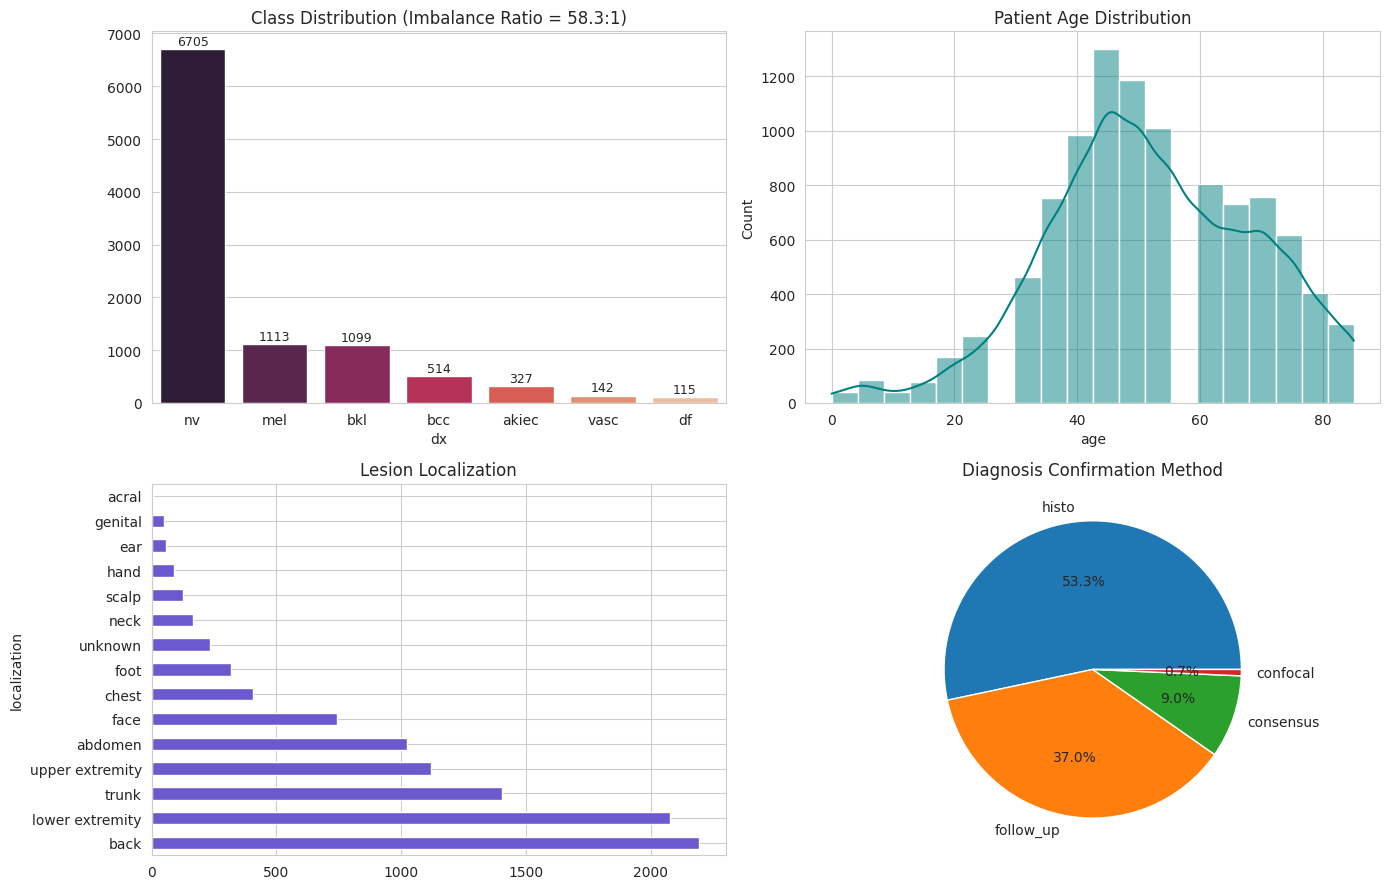

Missing age: 57
ผู้ป่วยไม่ซ้ำ: 7470 | รูปทั้งหมด: 10015


In [ ]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_style('whitegrid')
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# 1) Class imbalance
vc = df['dx'].value_counts()
sns.barplot(x=vc.index, y=vc.values, ax=ax[0,0], palette='rocket')
ax[0,0].set_title(f'Class Distribution (Imbalance Ratio = {vc.max()/vc.min():.1f}:1)')
for i,v in enumerate(vc.values): ax[0,0].text(i, v+80, str(v), ha='center', fontsize=9)

# 2) อายุ
sns.histplot(df['age'].dropna(), bins=20, kde=True, ax=ax[0,1], color='teal')
ax[0,1].set_title('Patient Age Distribution')

# 3) ตำแหน่งบนร่างกาย
df['localization'].value_counts().plot(kind='barh', ax=ax[1,0], color='slateblue')
ax[1,0].set_title('Lesion Localization')

# 4) วิธีวินิจฉัย
df['dx_type'].value_counts().plot(kind='pie', autopct='%1.1f%%', ax=ax[1,1])
ax[1,1].set_ylabel(''); ax[1,1].set_title('Diagnosis Confirmation Method')

plt.tight_layout(); plt.savefig(f'{PROJ}/figs/eda.png', dpi=130); plt.show()

print("Missing age:", df['age'].isna().sum())
print("ผู้ป่วยไม่ซ้ำ:", df['lesion_id'].nunique(), "| รูปทั้งหมด:", len(df))

ดูรูปตัวอย่างแต่ละคลาส

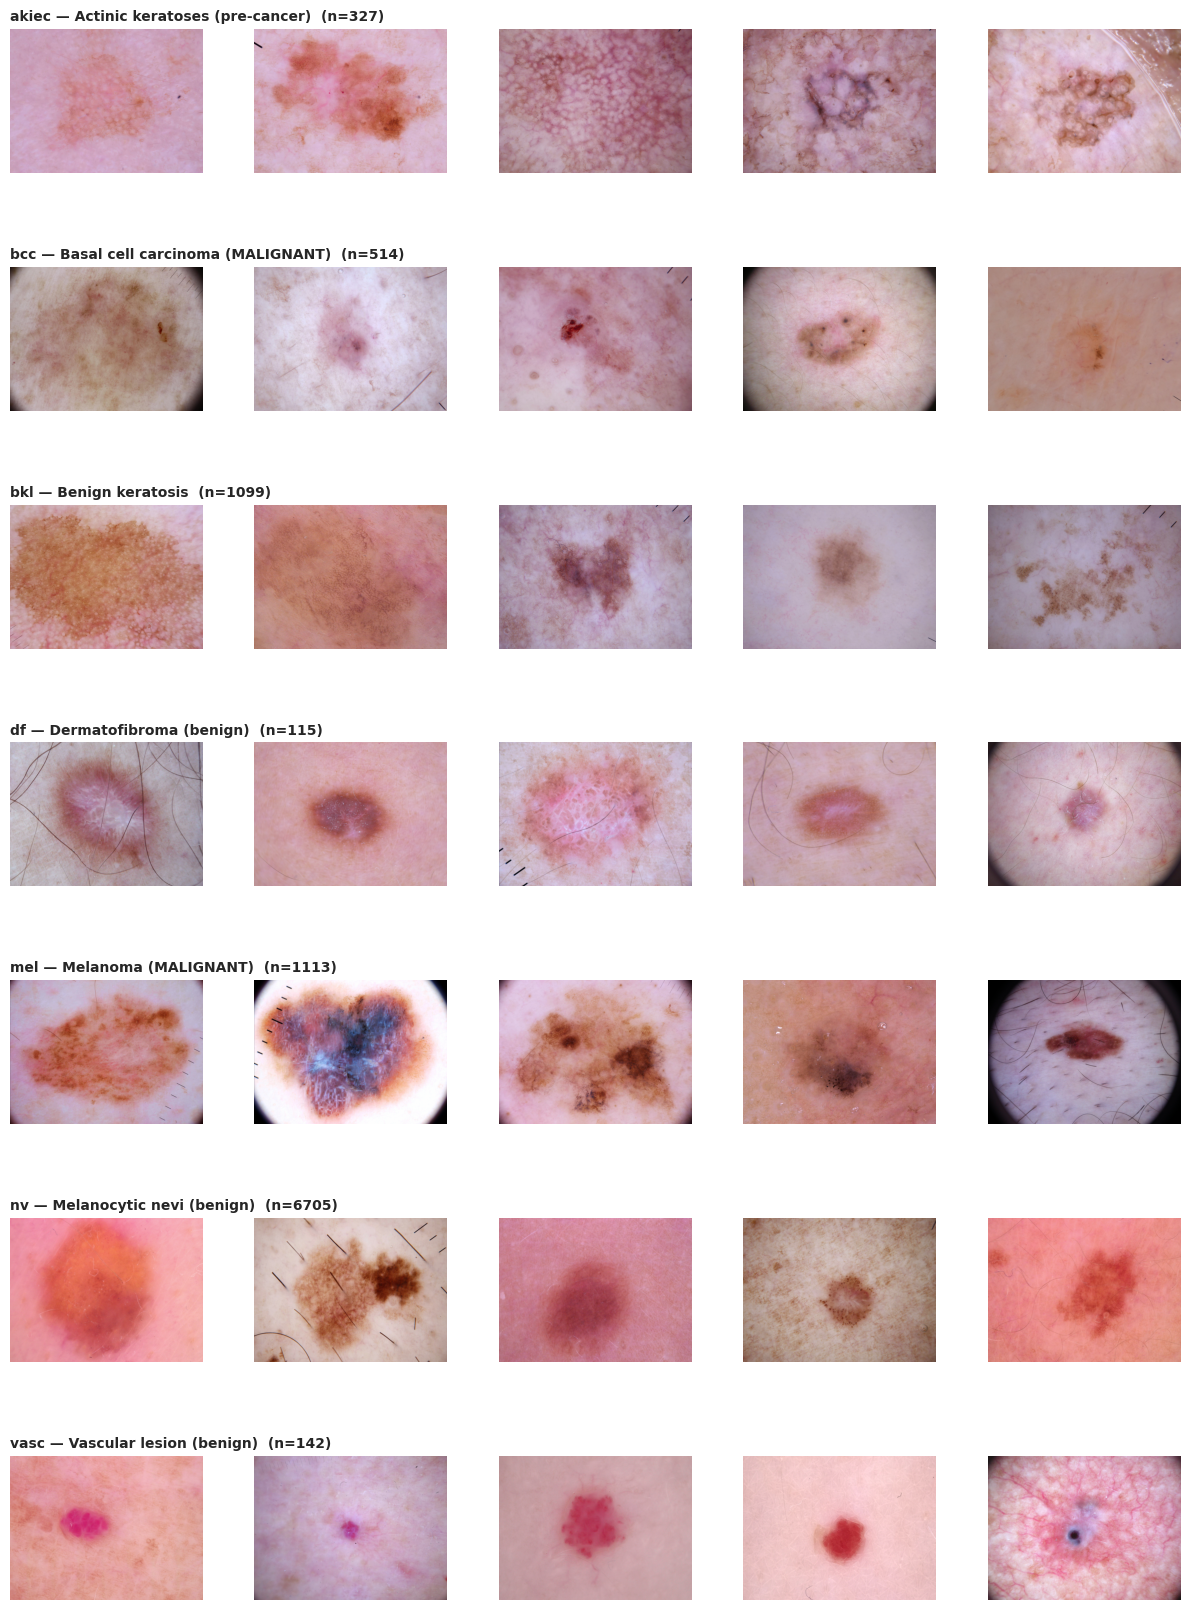

In [ ]:
from PIL import Image
fig, axes = plt.subplots(7, 5, figsize=(12, 17))
for r, c in enumerate(classes):
    sub = df[df['dx']==c].sample(5, random_state=42)
    for k, (_, row) in enumerate(sub.iterrows()):
        axes[r,k].imshow(Image.open(row['path'])); axes[r,k].axis('off')
        if k==0: axes[r,k].set_title(f"{c} — {LESION[c]}  (n={len(df[df['dx']==c])})",
                                     loc='left', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.savefig(f'{PROJ}/figs/samples.png', dpi=110); plt.show()

Split

In [ ]:
from sklearn.model_selection import train_test_split

les = df.groupby('lesion_id')['label'].first().reset_index()
tr_id, tmp_id = train_test_split(les, test_size=0.3, stratify=les['label'], random_state=42)
va_id, te_id  = train_test_split(tmp_id, test_size=0.5, stratify=tmp_id['label'], random_state=42)

train_df = df[df.lesion_id.isin(tr_id.lesion_id)].reset_index(drop=True)
val_df   = df[df.lesion_id.isin(va_id.lesion_id)].reset_index(drop=True)
test_df  = df[df.lesion_id.isin(te_id.lesion_id)].reset_index(drop=True)

print(f"Train {len(train_df)} | Val {len(val_df)} | Test {len(test_df)}")
assert set(train_df.lesion_id) & set(test_df.lesion_id) == set(), "มี leakage!"
print("✅ ไม่มี data leakage")

for d,n in [(train_df,'Train'),(val_df,'Val'),(test_df,'Test')]:
    print(n, dict(d['dx'].value_counts()))

train_df.to_csv(f'{PROJ}/train.csv', index=False)
val_df.to_csv(f'{PROJ}/val.csv', index=False)
test_df.to_csv(f'{PROJ}/test.csv', index=False)

Train 6981 | Val 1532 | Test 1502
✅ ไม่มี data leakage
Train {'nv': np.int64(4683), 'mel': np.int64(773), 'bkl': np.int64(772), 'bcc': np.int64(361), 'akiec': np.int64(222), 'vasc': np.int64(99), 'df': np.int64(71)}
Val {'nv': np.int64(1018), 'mel': np.int64(173), 'bkl': np.int64(160), 'bcc': np.int64(82), 'akiec': np.int64(53), 'df': np.int64(24), 'vasc': np.int64(22)}
Test {'nv': np.int64(1004), 'mel': np.int64(167), 'bkl': np.int64(167), 'bcc': np.int64(71), 'akiec': np.int64(52), 'vasc': np.int64(21), 'df': np.int64(20)}


## 🛠️ 2. Data Preprocessing & Augmentation
*   **Image Caching:** ทำการ Resize ภาพเป็น 256x256 และบันทึกลง Disk cache ล่วงหน้าเพื่อเร่งความเร็วในการโหลดข้อมูลระหว่างการเทรน (I/O Optimization)
*   **Data Augmentation:** ใช้ PyTorch `transforms` ในชุด Train (RandomHorizontalFlip, RandomVerticalFlip, ColorJitter, RandomRotation) เพื่อเพิ่มความหลากหลายของข้อมูลและลด Overfitting

Pre-resize cache ⚡

In [ ]:
import os, glob
from PIL import Image
from multiprocessing import Pool
from tqdm.auto import tqdm

CACHE = '/content/ham256'
os.makedirs(CACHE, exist_ok=True)

def resize_one(p):
    out = f"{CACHE}/{os.path.basename(p)}"
    if not os.path.exists(out):
        Image.open(p).convert('RGB').resize((256, 256), Image.BILINEAR).save(out, quality=95)
    return out

paths = glob.glob('/content/ham/**/*.jpg', recursive=True)
with Pool(os.cpu_count()) as pool:
    list(tqdm(pool.imap_unordered(resize_one, paths, chunksize=64), total=len(paths)))

print("cached:", len(os.listdir(CACHE)))

  0%|          | 0/20030 [00:00<?, ?it/s]

cached: 10015


ชี้ path ไปที่ cache + เติมค่าว่าง

In [ ]:
import pandas as pd, numpy as np

train_df = pd.read_csv(f'{PROJ}/train.csv')
val_df   = pd.read_csv(f'{PROJ}/val.csv')
test_df  = pd.read_csv(f'{PROJ}/test.csv')

AGE_MED = train_df['age'].median()          # เอาจาก train เท่านั้น กัน leakage
for d in (train_df, val_df, test_df):
    d['path'] = CACHE + '/' + d['image_id'] + '.jpg'
    d['age']  = d['age'].fillna(AGE_MED)

classes = ['akiec','bcc','bkl','df','mel','nv','vasc']
NUM_CLASSES = len(classes)
MALIGNANT = [classes.index('mel'), classes.index('bcc'), classes.index('akiec')]
print("median age =", AGE_MED, "| classes =", classes)

median age = 50.0 | classes = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


Dataset + Augmentation

In [ ]:
import torch, random
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

IMG = 224
MEAN, STD = [0.485,0.456,0.406], [0.229,0.224,0.225]

train_tf = T.Compose([
    T.RandomResizedCrop(IMG, scale=(0.7,1.0)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomRotation(30),
    T.ColorJitter(0.2,0.2,0.2,0.05),     # กันโมเดลจำสีแสงของกล้อง
    T.ToTensor(), T.Normalize(MEAN,STD),
    T.RandomErasing(p=0.25),
])
eval_tf = T.Compose([T.Resize(IMG), T.CenterCrop(IMG), T.ToTensor(), T.Normalize(MEAN,STD)])

class SkinDS(Dataset):
    def __init__(self, df, tf):
        self.df, self.tf = df.reset_index(drop=True), tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        return self.tf(Image.open(r['path']).convert('RGB')), int(r['label'])

BS = 64
def loader(df, tf, shuffle, sampler=None):
    return DataLoader(SkinDS(df,tf), batch_size=BS, shuffle=shuffle, sampler=sampler,
                      num_workers=2, pin_memory=True, drop_last=shuffle)

val_dl  = loader(val_df,  eval_tf, False)
test_dl = loader(test_df, eval_tf, False)
print(len(val_dl), len(test_dl))

24 24


Model + Loss (3 แบบสำหรับทดลองเทียบ)

In [ ]:
import timm, torch.nn as nn, torch.nn.functional as F

def build_model():
    m = timm.create_model('efficientnet_b0', pretrained=True, num_classes=NUM_CLASSES)
    return m.cuda()

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None):
        super().__init__(); self.g, self.w = gamma, weight
    def forward(self, logits, y):
        ce = F.cross_entropy(logits, y, weight=self.w, reduction='none')
        pt = torch.exp(-ce)
        return ((1-pt)**self.g * ce).mean()

cnt = train_df['label'].value_counts().sort_index().values
cls_w = torch.tensor(cnt.sum()/(NUM_CLASSES*cnt), dtype=torch.float32).cuda()
print("class weights:", dict(zip(classes, cls_w.cpu().numpy().round(2))))

class weights: {'akiec': np.float32(4.49), 'bcc': np.float32(2.76), 'bkl': np.float32(1.29), 'df': np.float32(14.05), 'mel': np.float32(1.29), 'nv': np.float32(0.21), 'vasc': np.float32(10.07)}


Train / Eval function

In [ ]:
from sklearn.metrics import f1_score, balanced_accuracy_score, classification_report
import time, copy

@torch.no_grad()
def evaluate(model, dl):
    model.eval(); P, Y = [], []
    for x,y in dl:
        with torch.autocast('cuda', torch.float16):
            o = model(x.cuda(non_blocking=True))
        P.append(o.float().softmax(1).cpu()); Y.append(y)
    P, Y = torch.cat(P), torch.cat(Y)
    pred = P.argmax(1)
    return dict(acc=(pred==Y).float().mean().item(),
                f1=f1_score(Y,pred,average='macro'),
                bacc=balanced_accuracy_score(Y,pred),
                mel_rec=((pred==4)&(Y==4)).sum().item()/max((Y==4).sum().item(),1)
               ), P.numpy(), Y.numpy()

def train(tag, criterion, train_loader, epochs=10, lr=3e-4):
    model = build_model()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, lr, epochs=epochs, steps_per_epoch=len(train_loader))
    scaler = torch.amp.GradScaler()
    best, hist = -1, []
    for ep in range(epochs):
        model.train(); tl, t0 = 0, time.time()
        for x,y in train_loader:
            x,y = x.cuda(non_blocking=True), y.cuda(non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda', torch.float16):
                loss = criterion(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()
            tl += loss.item()
        m,_,_ = evaluate(model, val_dl)
        hist.append(dict(ep=ep+1, loss=tl/len(train_loader), **m))
        print(f"[{tag}] ep{ep+1:02d} loss {tl/len(train_loader):.3f} | "
              f"acc {m['acc']:.4f} F1 {m['f1']:.4f} bAcc {m['bacc']:.4f} melR {m['mel_rec']:.3f} "
              f"| {time.time()-t0:.0f}s")
        if m['f1'] > best:
            best = m['f1']; torch.save(model.state_dict(), f'{PROJ}/ckpt/{tag}.pt')
    pd.DataFrame(hist).to_csv(f'{PROJ}/ckpt/{tag}_hist.csv', index=False)
    print(f"✅ {tag} best val macro-F1 = {best:.4f}")
    return model, pd.DataFrame(hist)

รัน Experiment A (Baseline) 🚀


In [ ]:
train_dl_plain = loader(train_df, train_tf, shuffle=True)
model_A, hist_A = train('A_baseline', nn.CrossEntropyLoss(label_smoothing=0.05), train_dl_plain, epochs=10)

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_1554/523136325.py:32: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()


[A_baseline] ep01 loss 2.788 | acc 0.6554 F1 0.3080 bAcc 0.3119 melR 0.428 | 79s
[A_baseline] ep02 loss 1.141 | acc 0.7056 F1 0.4112 bAcc 0.3839 melR 0.306 | 64s
[A_baseline] ep03 loss 0.876 | acc 0.7631 F1 0.5104 bAcc 0.4899 melR 0.295 | 67s
[A_baseline] ep04 loss 0.755 | acc 0.7813 F1 0.5377 bAcc 0.4985 melR 0.468 | 67s
[A_baseline] ep05 loss 0.680 | acc 0.7931 F1 0.5537 bAcc 0.5196 melR 0.526 | 65s
[A_baseline] ep06 loss 0.615 | acc 0.8022 F1 0.5993 bAcc 0.5562 melR 0.543 | 67s
[A_baseline] ep07 loss 0.580 | acc 0.8022 F1 0.6009 bAcc 0.5607 melR 0.538 | 65s
[A_baseline] ep08 loss 0.553 | acc 0.8114 F1 0.6355 bAcc 0.6052 melR 0.543 | 66s
[A_baseline] ep09 loss 0.521 | acc 0.8140 F1 0.6321 bAcc 0.5885 melR 0.555 | 69s
[A_baseline] ep10 loss 0.514 | acc 0.8055 F1 0.6313 bAcc 0.5953 melR 0.561 | 71s
✅ A_baseline best val macro-F1 = 0.6355


# **Experiment B (class-weighted) + C (focal loss) + ตารางเปรียบเทียบ**

Experiment B: Class-Weighted CE

In [ ]:
model_B, hist_B = train('B_weighted',
                        nn.CrossEntropyLoss(weight=cls_w, label_smoothing=0.05),
                        train_dl_plain, epochs=10)


/tmp/ipykernel_1554/523136325.py:32: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()


[B_weighted] ep01 loss 4.593 | acc 0.1384 F1 0.1246 bAcc 0.2096 melR 0.225 | 70s
[B_weighted] ep02 loss 2.611 | acc 0.2265 F1 0.2006 bAcc 0.3581 melR 0.295 | 71s
[B_weighted] ep03 loss 1.995 | acc 0.3407 F1 0.2762 bAcc 0.4454 melR 0.306 | 67s
[B_weighted] ep04 loss 1.674 | acc 0.4863 F1 0.3752 bAcc 0.5753 melR 0.434 | 70s
[B_weighted] ep05 loss 1.557 | acc 0.4889 F1 0.4016 bAcc 0.6110 melR 0.370 | 82s
[B_weighted] ep06 loss 1.426 | acc 0.5163 F1 0.4212 bAcc 0.6326 melR 0.601 | 97s
[B_weighted] ep07 loss 1.326 | acc 0.5555 F1 0.4361 bAcc 0.6273 melR 0.549 | 68s
[B_weighted] ep08 loss 1.308 | acc 0.5633 F1 0.4466 bAcc 0.6369 melR 0.671 | 69s
[B_weighted] ep09 loss 1.284 | acc 0.5744 F1 0.4607 bAcc 0.6398 melR 0.705 | 66s
[B_weighted] ep10 loss 1.281 | acc 0.5803 F1 0.4614 bAcc 0.6420 melR 0.711 | 67s
✅ B_weighted best val macro-F1 = 0.4614


Experiment C: Focal Loss + Balanced Sampler

In [ ]:
from torch.utils.data import WeightedRandomSampler

sw = cls_w.cpu().numpy()[train_df['label'].values]      # น้ำหนักต่อตัวอย่าง
sampler = WeightedRandomSampler(torch.DoubleTensor(sw), len(sw), replacement=True)
train_dl_bal = loader(train_df, train_tf, shuffle=False, sampler=sampler)

model_C, hist_C = train('C_focal_sampler',
                        FocalLoss(gamma=2.0, weight=cls_w),
                        train_dl_bal, epochs=10)

/tmp/ipykernel_1554/523136325.py:32: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()


[C_focal_sampler] ep01 loss 11.633 | acc 0.0946 F1 0.1097 bAcc 0.3363 melR 0.231 | 68s
[C_focal_sampler] ep02 loss 3.123 | acc 0.1834 F1 0.2168 bAcc 0.4914 melR 0.376 | 66s
[C_focal_sampler] ep03 loss 1.653 | acc 0.3211 F1 0.3116 bAcc 0.5912 melR 0.566 | 70s
[C_focal_sampler] ep04 loss 1.034 | acc 0.3642 F1 0.3521 bAcc 0.6080 melR 0.590 | 66s
[C_focal_sampler] ep05 loss 0.824 | acc 0.3342 F1 0.3167 bAcc 0.5677 melR 0.520 | 65s
[C_focal_sampler] ep06 loss 0.670 | acc 0.4054 F1 0.3661 bAcc 0.6010 melR 0.676 | 66s
[C_focal_sampler] ep07 loss 0.545 | acc 0.4262 F1 0.3899 bAcc 0.6182 melR 0.688 | 66s
[C_focal_sampler] ep08 loss 0.435 | acc 0.4413 F1 0.3895 bAcc 0.6247 melR 0.624 | 66s
[C_focal_sampler] ep09 loss 0.432 | acc 0.4478 F1 0.4020 bAcc 0.6322 melR 0.647 | 68s
[C_focal_sampler] ep10 loss 0.403 | acc 0.4543 F1 0.4255 bAcc 0.6223 melR 0.717 | 66s
✅ C_focal_sampler best val macro-F1 = 0.4255


กราฟเปรียบเทียบ

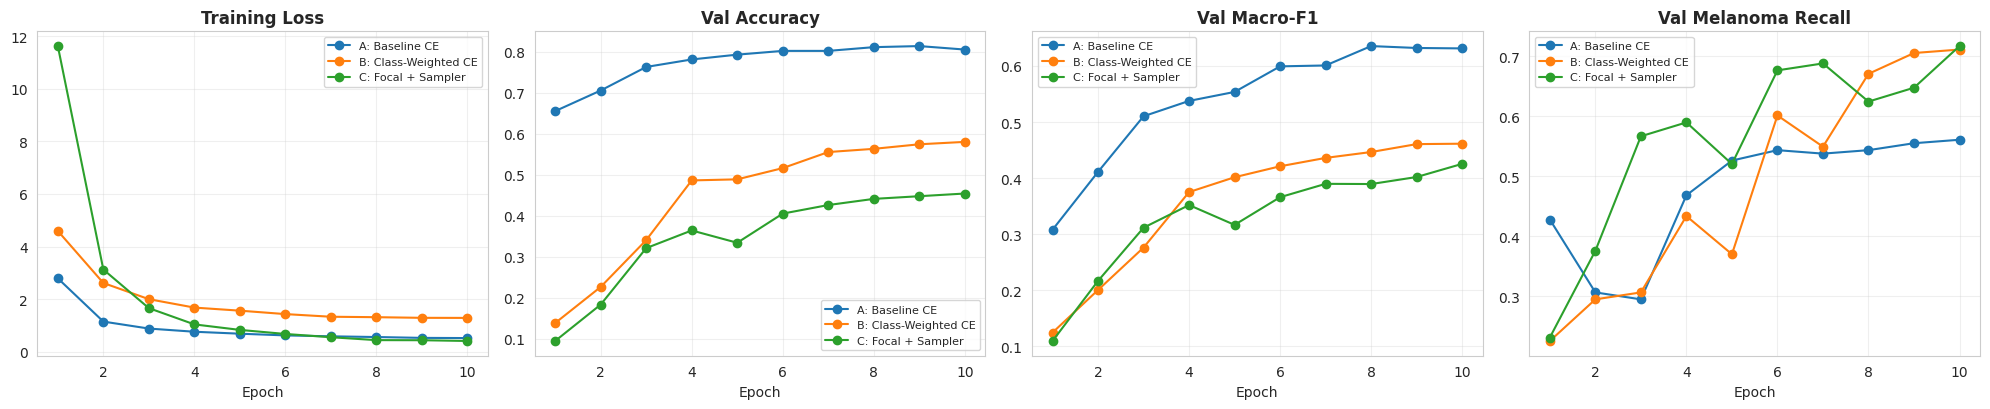

In [ ]:
import matplotlib.pyplot as plt

runs = {'A: Baseline CE': hist_A, 'B: Class-Weighted CE': hist_B, 'C: Focal + Sampler': hist_C}
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
for name, h in runs.items():
    ax[0].plot(h.ep, h.loss,    marker='o', label=name)
    ax[1].plot(h.ep, h.acc,     marker='o', label=name)
    ax[2].plot(h.ep, h.f1,      marker='o', label=name)
    ax[3].plot(h.ep, h.mel_rec, marker='o', label=name)
for a, t in zip(ax, ['Training Loss','Val Accuracy','Val Macro-F1','Val Melanoma Recall']):
    a.set_title(t, fontweight='bold'); a.set_xlabel('Epoch'); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{PROJ}/figs/curves.png', dpi=130); plt.show()

ประเมินบน Test set ทั้ง 3 โมเดล

In [ ]:
results, probs_store = [], {}
for tag, mdl in [('A_baseline',model_A), ('B_weighted',model_B), ('C_focal_sampler',model_C)]:
    mdl.load_state_dict(torch.load(f'{PROJ}/ckpt/{tag}.pt'))   # โหลด best epoch
    m, P, Y = evaluate(mdl, test_dl)
    probs_store[tag] = (P, Y)
    results.append(dict(Model=tag, **{k: round(v,4) for k,v in m.items()}))

res_df = pd.DataFrame(results).rename(columns={
    'acc':'Accuracy','f1':'Macro-F1','bacc':'Balanced-Acc','mel_rec':'Melanoma-Recall'})
res_df.to_csv(f'{PROJ}/results_test.csv', index=False)
print(res_df.to_string(index=False))

          Model  Accuracy  Macro-F1  Balanced-Acc  Melanoma-Recall
     A_baseline    0.7889    0.6486        0.6319           0.5030
     B_weighted    0.5473    0.4483        0.6831           0.6048
C_focal_sampler    0.4394    0.4359        0.6630           0.6108


Confusion Matrix เทียบ 3 โมเดล

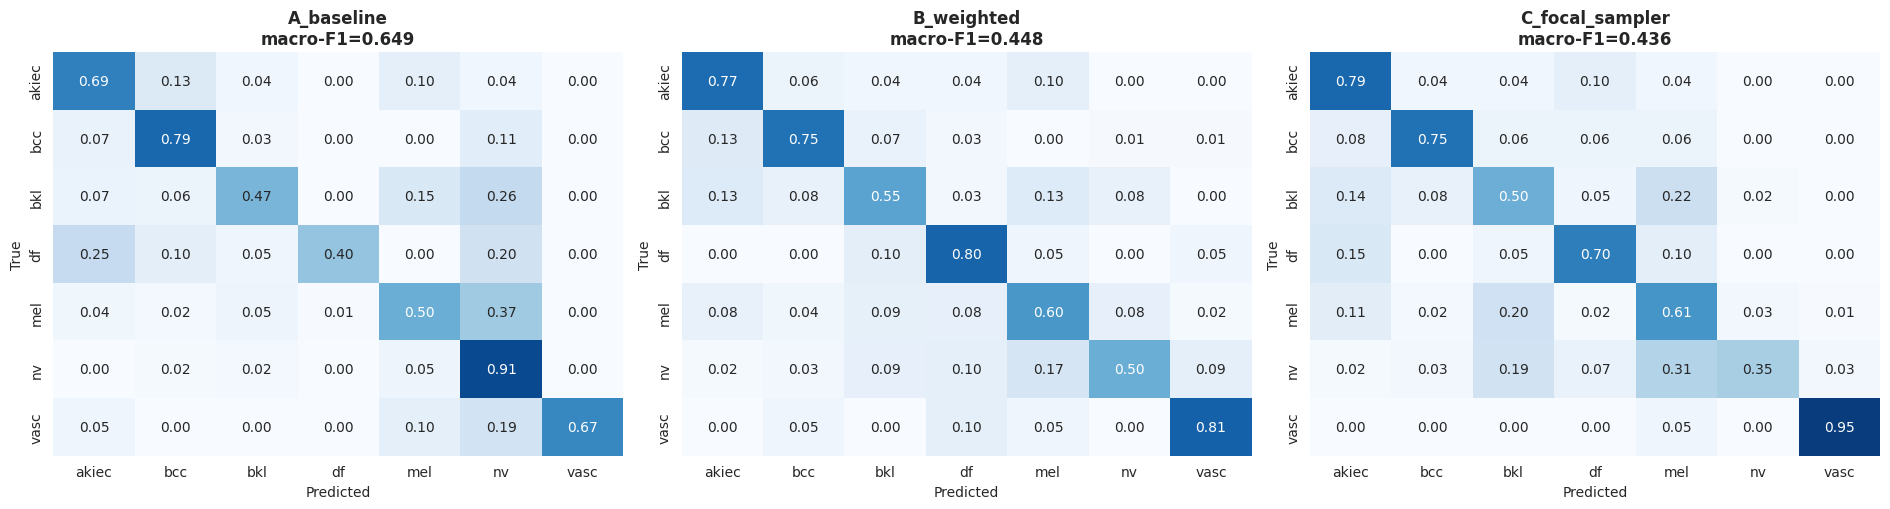

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns, numpy as np

fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
for i,(tag,(P,Y)) in enumerate(probs_store.items()):
    cm = confusion_matrix(Y, P.argmax(1), normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', cbar=False,
                xticklabels=classes, yticklabels=classes, ax=ax[i], vmin=0, vmax=1)
    ax[i].set_title(f'{tag}\nmacro-F1={f1_score(Y,P.argmax(1),average="macro"):.3f}', fontweight='bold')
    ax[i].set_xlabel('Predicted'); ax[i].set_ylabel('True')
plt.tight_layout(); plt.savefig(f'{PROJ}/figs/confusion.png', dpi=130); plt.show()

Classification report ตัวเต็มของโมเดลที่ดีที่สุด

In [ ]:
best_tag = res_df.sort_values('Macro-F1', ascending=False).iloc[0]['Model']
P, Y = probs_store[best_tag]
print(f"===== BEST MODEL: {best_tag} =====\n")
print(classification_report(Y, P.argmax(1), target_names=classes, digits=4))

rep = pd.DataFrame(classification_report(Y, P.argmax(1), target_names=classes,
                                         digits=4, output_dict=True)).T
rep.to_csv(f'{PROJ}/classification_report.csv')
rep.round(4)

===== BEST MODEL: A_baseline =====

              precision    recall  f1-score   support

       akiec     0.5538    0.6923    0.6154        52
         bcc     0.5773    0.7887    0.6667        71
         bkl     0.6724    0.4671    0.5512       167
          df     0.8000    0.4000    0.5333        20
         mel     0.5030    0.5030    0.5030       167
          nv     0.8808    0.9054    0.8929      1004
        vasc     0.9333    0.6667    0.7778        21

    accuracy                         0.7889      1502
   macro avg     0.7030    0.6319    0.6486      1502
weighted avg     0.7896    0.7889    0.7849      1502



,precision,recall,f1-score,support
akiec,0.5538,0.6923,0.6154,52.0000
bcc,0.5773,0.7887,0.6667,71.0000
bkl,0.6724,0.4671,0.5512,167.0000
df,0.8000,0.4000,0.5333,20.0000
mel,0.5030,0.5030,0.5030,167.0000
nv,0.8808,0.9054,0.8929,1004.0000
vasc,0.9333,0.6667,0.7778,21.0000
accuracy,0.7889,0.7889,0.7889,0.7889
macro avg,0.7030,0.6319,0.6486,1502.0000
weighted avg,0.7896,0.7889,0.7849,1502.0000


# **Post-hoc Logit Adjustment + Cost-Sensitive Threshold + Grad-CAM**

ดึง val probabilities ของ Model A


In [ ]:
import numpy as np
model_A.load_state_dict(torch.load(f'{PROJ}/ckpt/A_baseline.pt'))
_, Pv, Yv = evaluate(model_A, val_dl)
Pt, Yt = probs_store['A_baseline']
prior = (train_df['label'].value_counts().sort_index().values / len(train_df))
print("prior:", dict(zip(classes, prior.round(4))))

prior: {'akiec': np.float64(0.0318), 'bcc': np.float64(0.0517), 'bkl': np.float64(0.1106), 'df': np.float64(0.0102), 'mel': np.float64(0.1107), 'nv': np.float64(0.6708), 'vasc': np.float64(0.0142)}


Logit Adjustment: จูน τ บน val ⭐

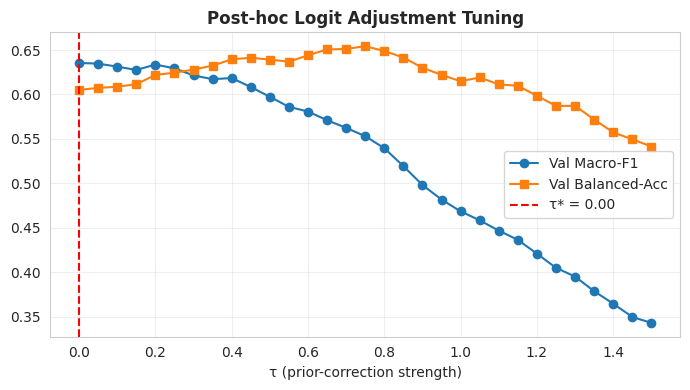

τ* = 0.00 | val macro-F1 = 0.6355


In [ ]:
logpv, logpt = np.log(Pv + 1e-12), np.log(Pt + 1e-12)
rows, best = [], (0, -1)
for tau in np.arange(0, 1.55, 0.05):
    pred = (logpv - tau*np.log(prior)).argmax(1)
    f1 = f1_score(Yv, pred, average='macro')
    rows.append(dict(tau=round(tau,2), val_f1=f1,
                     val_bacc=balanced_accuracy_score(Yv, pred)))
    if f1 > best[1]: best = (tau, f1)
tau_star = best[0]
tdf = pd.DataFrame(rows)

plt.figure(figsize=(7,4))
plt.plot(tdf.tau, tdf.val_f1, marker='o', label='Val Macro-F1')
plt.plot(tdf.tau, tdf.val_bacc, marker='s', label='Val Balanced-Acc')
plt.axvline(tau_star, ls='--', c='r', label=f'τ* = {tau_star:.2f}')
plt.xlabel('τ (prior-correction strength)'); plt.grid(alpha=.3); plt.legend()
plt.title('Post-hoc Logit Adjustment Tuning', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{PROJ}/figs/tau_tuning.png', dpi=130); plt.show()
print(f"τ* = {tau_star:.2f} | val macro-F1 = {best[1]:.4f}")

ใช้ τ* กับ Test แล้วเทียบ 4 โมเดล

In [ ]:
pred_adj = (logpt - tau_star*np.log(prior)).argmax(1)
row_D = dict(Model=f'D_A+LogitAdj(τ={tau_star:.2f})',
             Accuracy=round((pred_adj==Yt).mean(),4),
             **{'Macro-F1': round(f1_score(Yt,pred_adj,average='macro'),4),
                'Balanced-Acc': round(balanced_accuracy_score(Yt,pred_adj),4),
                'Melanoma-Recall': round(((pred_adj==4)&(Yt==4)).sum()/ (Yt==4).sum(),4)})

final_df = pd.concat([res_df, pd.DataFrame([row_D])], ignore_index=True)
final_df.to_csv(f'{PROJ}/results_final.csv', index=False)
print(final_df.to_string(index=False))
print("\n", classification_report(Yt, pred_adj, target_names=classes, digits=4))

               Model  Accuracy  Macro-F1  Balanced-Acc  Melanoma-Recall
          A_baseline    0.7889    0.6486        0.6319           0.5030
          B_weighted    0.5473    0.4483        0.6831           0.6048
     C_focal_sampler    0.4394    0.4359        0.6630           0.6108
D_A+LogitAdj(τ=0.00)    0.7889    0.6486        0.6319           0.5030

               precision    recall  f1-score   support

       akiec     0.5538    0.6923    0.6154        52
         bcc     0.5773    0.7887    0.6667        71
         bkl     0.6724    0.4671    0.5512       167
          df     0.8000    0.4000    0.5333        20
         mel     0.5030    0.5030    0.5030       167
          nv     0.8808    0.9054    0.8929      1004
        vasc     0.9333    0.6667    0.7778        21

    accuracy                         0.7889      1502
   macro avg     0.7030    0.6319    0.6486      1502
weighted avg     0.7896    0.7889    0.7849      1502



Clinical Screening: Malignant vs Benign ⭐⭐



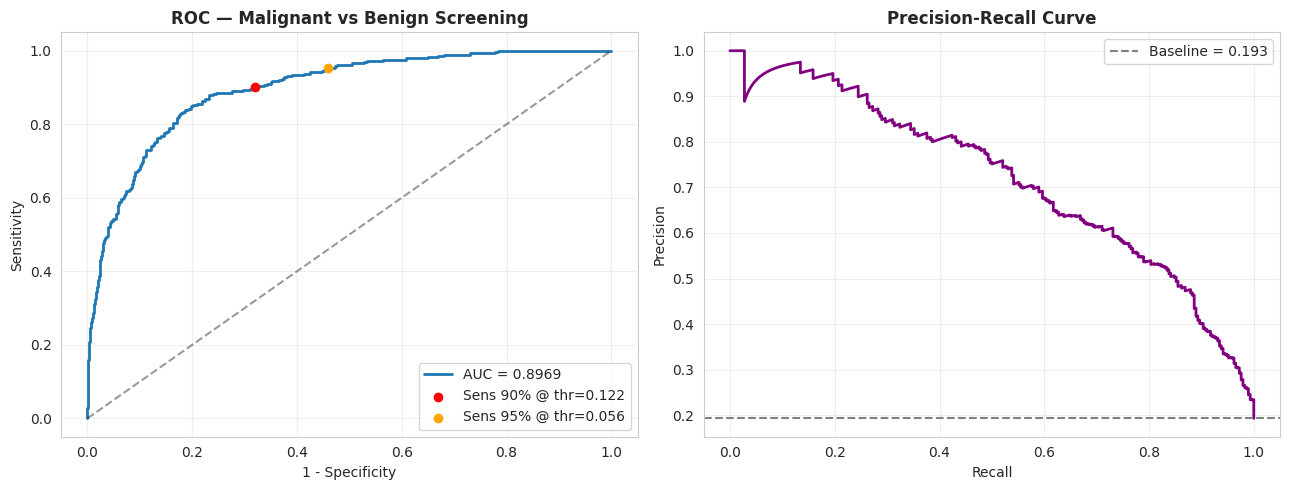

Default thr=0.5  → Sens 0.669 | Spec 0.909
Operating @90%   → Sens 0.900 | Spec 0.680  (thr=0.122)
Operating @95%   → Sens 0.952 | Spec 0.540  (thr=0.056)

มะเร็งที่ยังพลาดที่ 95% sensitivity: 13 / 290 เคส


In [ ]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve

MAL_IDX = [classes.index(c) for c in ['mel','bcc','akiec']]
y_bin  = np.isin(Yt, MAL_IDX).astype(int)
p_mal  = Pt[:, MAL_IDX].sum(1)

fpr, tpr, thr = roc_curve(y_bin, p_mal); A = auc(fpr, tpr)
i90 = np.where(tpr >= 0.90)[0][0]; t90 = thr[i90]
i95 = np.where(tpr >= 0.95)[0][0]; t95 = thr[i95]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(fpr, tpr, lw=2, label=f'AUC = {A:.4f}')
ax[0].plot([0,1],[0,1],'k--',alpha=.4)
ax[0].scatter(fpr[i90], tpr[i90], c='r', zorder=5, label=f'Sens 90% @ thr={t90:.3f}')
ax[0].scatter(fpr[i95], tpr[i95], c='orange', zorder=5, label=f'Sens 95% @ thr={t95:.3f}')
ax[0].set_xlabel('1 - Specificity'); ax[0].set_ylabel('Sensitivity')
ax[0].set_title('ROC — Malignant vs Benign Screening', fontweight='bold')
ax[0].legend(); ax[0].grid(alpha=.3)

pr, rc, _ = precision_recall_curve(y_bin, p_mal)
ax[1].plot(rc, pr, lw=2, color='purple')
ax[1].axhline(y_bin.mean(), ls='--', c='gray', label=f'Baseline = {y_bin.mean():.3f}')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-Recall Curve', fontweight='bold'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{PROJ}/figs/roc_screening.png', dpi=130); plt.show()

print(f"Default thr=0.5  → Sens {tpr[np.abs(thr-0.5).argmin()]:.3f} | Spec {1-fpr[np.abs(thr-0.5).argmin()]:.3f}")
print(f"Operating @90%   → Sens {tpr[i90]:.3f} | Spec {1-fpr[i90]:.3f}  (thr={t90:.3f})")
print(f"Operating @95%   → Sens {tpr[i95]:.3f} | Spec {1-fpr[i95]:.3f}  (thr={t95:.3f})")
print(f"\nมะเร็งที่ยังพลาดที่ 95% sensitivity: {int((1-tpr[i95])*y_bin.sum())} / {y_bin.sum()} เคส")

Grad-CAM ⭐⭐⭐ (ภาพเด่นที่สุดในสไลด์)

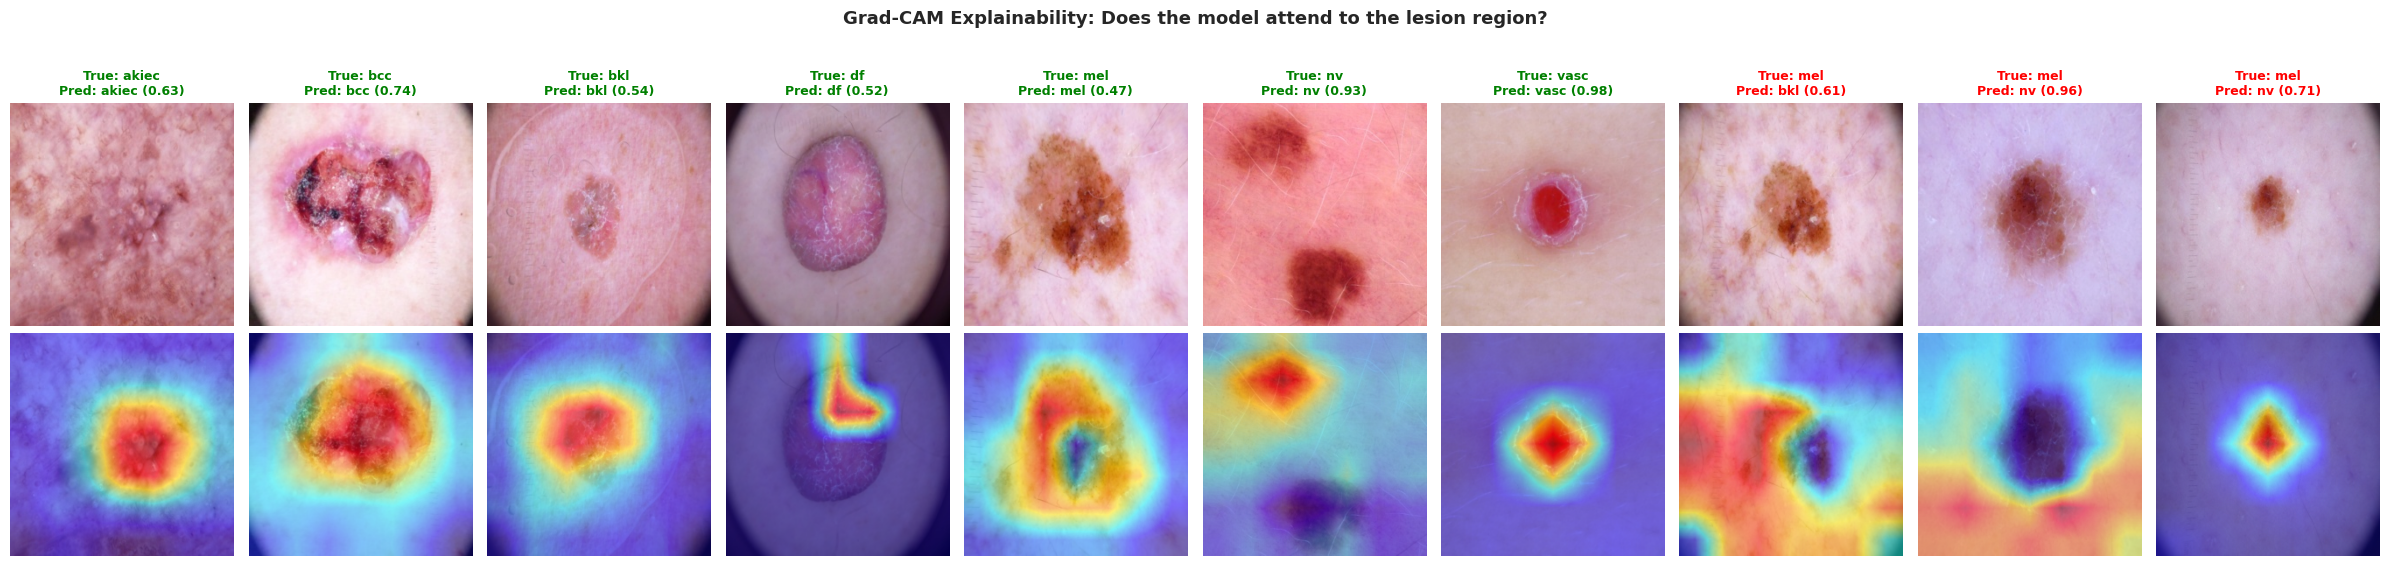

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

model_A.eval()
cam = GradCAM(model=model_A, target_layers=[model_A.conv_head])
inv = lambda t: (t.permute(1,2,0).numpy()*np.array(STD)+np.array(MEAN)).clip(0,1)

pred_t = Pt.argmax(1)
picks = []
for c in range(NUM_CLASSES):                     # 1 ตัวอย่างที่ทายถูกต่อคลาส
    idx = np.where((Yt==c)&(pred_t==c))[0]
    if len(idx): picks.append((idx[0], 'CORRECT'))
mis = np.where((Yt==4)&(pred_t!=4))[0][:3]       # melanoma ที่พลาด 3 เคส
picks += [(i,'MISSED MEL') for i in mis]

plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(2, len(picks), figsize=(2.4*len(picks), 5.6))
for k,(i,tagx) in enumerate(picks):
    x, y = SkinDS(test_df, eval_tf)[i]
    rgb = inv(x)
    g = cam(input_tensor=x.unsqueeze(0).cuda(), targets=[ClassifierOutputTarget(int(pred_t[i]))])[0]
    axes[0,k].imshow(rgb); axes[0,k].axis('off')
    axes[0,k].set_title(f"True: {classes[Yt[i]]}\nPred: {classes[pred_t[i]]} ({Pt[i].max():.2f})",
                        fontsize=9, color='green' if tagx=='CORRECT' else 'red', fontweight='bold')
    axes[1,k].imshow(show_cam_on_image(rgb, g, use_rgb=True)); axes[1,k].axis('off')
plt.suptitle('Grad-CAM Explainability: Does the model attend to the lesion region?',
             fontweight='bold', fontsize=13, y=1.03)
plt.tight_layout(); plt.savefig(f'{PROJ}/figs/gradcam.png', dpi=130, bbox_inches='tight'); plt.show()

เก็บ operating point ตัวที่ 2 (τ สำหรับ bAcc)

In [ ]:
tau_b = tdf.loc[tdf.val_bacc.idxmax(), 'tau']
pred_e = (logpt - tau_b*np.log(prior)).argmax(1)
row_E = {'Model': f'E_A+LogitAdj(tau={tau_b:.2f}, bAcc-opt)',
         'Accuracy': round((pred_e==Yt).mean(),4),
         'Macro-F1': round(f1_score(Yt,pred_e,average='macro'),4),
         'Balanced-Acc': round(balanced_accuracy_score(Yt,pred_e),4),
         'Melanoma-Recall': round(((pred_e==4)&(Yt==4)).sum()/(Yt==4).sum(),4)}

final_df = pd.concat([res_df, pd.DataFrame([row_D, row_E])], ignore_index=True)
final_df.to_csv(f'{PROJ}/results_final.csv', index=False)
print(f"tau_bAcc* = {tau_b:.2f}\n")
print(final_df.to_string(index=False))

tau_bAcc* = 0.75

                           Model  Accuracy  Macro-F1  Balanced-Acc  Melanoma-Recall
                      A_baseline    0.7889    0.6486        0.6319           0.5030
                      B_weighted    0.5473    0.4483        0.6831           0.6048
                 C_focal_sampler    0.4394    0.4359        0.6630           0.6108
            D_A+LogitAdj(τ=0.00)    0.7889    0.6486        0.6319           0.5030
E_A+LogitAdj(tau=0.75, bAcc-opt)    0.6977    0.5517        0.6888           0.5449


กราฟสรุป trade-off (ภาพปิดของ report) ⭐

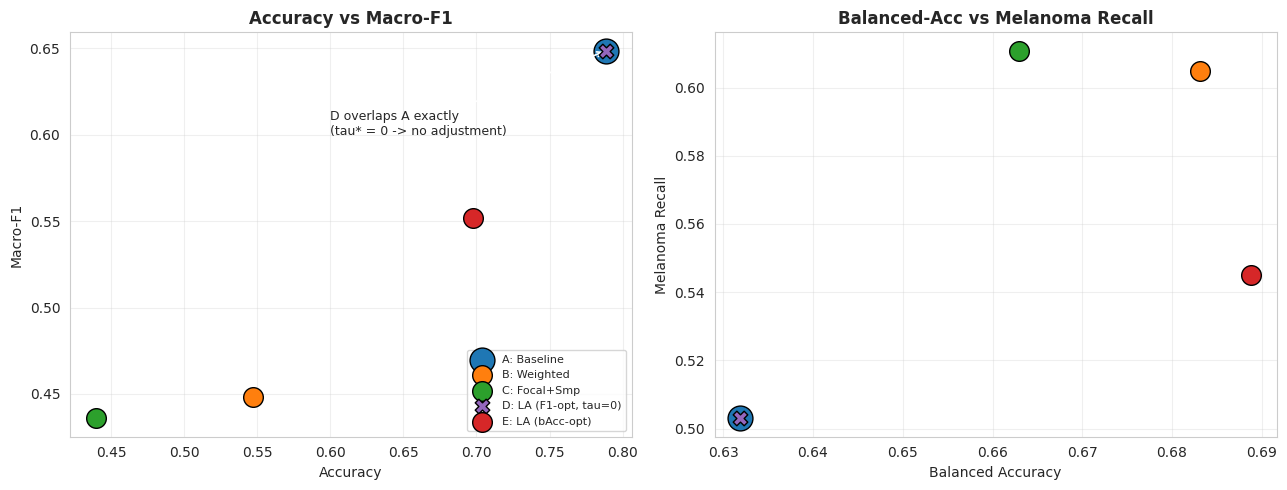

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
lbl = ['A: Baseline','B: Weighted','C: Focal+Smp','D: LA (F1-opt, tau=0)','E: LA (bAcc-opt)']
col = ['#1f77b4','#ff7f0e','#2ca02c','#9467bd','#d62728']
mk  = ['o','o','o','X','o']        # D ใช้กากบาท เห็นทะลุจุด A
sz  = [320,200,200,110,200]        # A วงใหญ่กว่า D
for n,(_,r) in enumerate(final_df.iterrows()):
    ax[0].scatter(r['Accuracy'], r['Macro-F1'], s=sz[n], c=col[n], marker=mk[n],
                  label=lbl[n], edgecolor='k', zorder=3+n)
    ax[1].scatter(r['Balanced-Acc'], r['Melanoma-Recall'], s=sz[n], c=col[n], marker=mk[n],
                  edgecolor='k', zorder=3+n)
ax[0].annotate('D overlaps A exactly\n(tau* = 0 -> no adjustment)', xy=(0.7889,0.6486),
               xytext=(0.60,0.60), fontsize=9, arrowprops=dict(arrowstyle='->', lw=1.2))
ax[0].set_xlabel('Accuracy'); ax[0].set_ylabel('Macro-F1')
ax[0].set_title('Accuracy vs Macro-F1', fontweight='bold'); ax[0].legend(fontsize=8, loc='lower right'); ax[0].grid(alpha=.3)
ax[1].set_xlabel('Balanced Accuracy'); ax[1].set_ylabel('Melanoma Recall')
ax[1].set_title('Balanced-Acc vs Melanoma Recall', fontweight='bold'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{PROJ}/figs/tradeoff.png', dpi=130); plt.show()

# **Multimodal Fusion (Experiment F) + Gradio Demo**

เตรียม metadata features

In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CAT = ['sex','localization']
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(train_df[CAT])
sc  = StandardScaler().fit(train_df[['age']])

def make_meta(d):
    return np.hstack([sc.transform(d[['age']]), ohe.transform(d[CAT])]).astype('float32')

META_DIM = make_meta(train_df).shape[1]
meta_cache = {'train': make_meta(train_df), 'val': make_meta(val_df), 'test': make_meta(test_df)}
print("META_DIM =", META_DIM)

META_DIM = 19


Dataset + Model แบบ 2 ทาง

In [ ]:
class MultiDS(Dataset):
    def __init__(self, df, meta, tf):
        self.df, self.meta, self.tf = df.reset_index(drop=True), meta, tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        return self.tf(Image.open(r['path']).convert('RGB')), torch.from_numpy(self.meta[i]), int(r['label'])

def mloader(df, meta, tf, shuffle):
    return DataLoader(MultiDS(df,meta,tf), batch_size=BS, shuffle=shuffle,
                      num_workers=2, pin_memory=True, drop_last=shuffle)

class MultimodalNet(nn.Module):
    def __init__(self, meta_dim, n_cls):
        super().__init__()
        self.cnn = timm.create_model('efficientnet_b0', pretrained=True, num_classes=0)
        d = self.cnn.num_features                       # 1280
        self.mlp = nn.Sequential(nn.Linear(meta_dim,64), nn.BatchNorm1d(64), nn.ReLU(),
                                 nn.Dropout(0.3), nn.Linear(64,64), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(d+64, n_cls))
    def forward(self, x, m):
        return self.head(torch.cat([self.cnn(x), self.mlp(m)], dim=1))

tr_mdl = mloader(train_df, meta_cache['train'], train_tf, True)
va_mdl = mloader(val_df,   meta_cache['val'],   eval_tf, False)
te_mdl = mloader(test_df,  meta_cache['test'],  eval_tf, False)

Train Multimodal

In [ ]:
@torch.no_grad()
def eval_multi(model, dl):
    model.eval(); P,Y = [],[]
    for x,m,y in dl:
        with torch.autocast('cuda', torch.float16):
            o = model(x.cuda(non_blocking=True), m.cuda(non_blocking=True))
        P.append(o.float().softmax(1).cpu()); Y.append(y)
    P,Y = torch.cat(P), torch.cat(Y); pred = P.argmax(1)
    return dict(acc=(pred==Y).float().mean().item(), f1=f1_score(Y,pred,average='macro'),
                bacc=balanced_accuracy_score(Y,pred),
                mel_rec=((pred==4)&(Y==4)).sum().item()/max((Y==4).sum().item(),1)), P.numpy(), Y.numpy()

model_F = MultimodalNet(META_DIM, NUM_CLASSES).cuda()
crit = nn.CrossEntropyLoss(label_smoothing=0.05)
opt = torch.optim.AdamW(model_F.parameters(), lr=3e-4, weight_decay=1e-4)
EPOCHS = 10
sch = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-4, epochs=EPOCHS, steps_per_epoch=len(tr_mdl))
scaler = torch.amp.GradScaler(); best, hist_F = -1, []

for ep in range(EPOCHS):
    model_F.train(); tl, t0 = 0, time.time()
    for x,m,y in tr_mdl:
        x,m,y = x.cuda(non_blocking=True), m.cuda(non_blocking=True), y.cuda(non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda', torch.float16):
            loss = crit(model_F(x,m), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()
        tl += loss.item()
    mt,_,_ = eval_multi(model_F, va_mdl)
    hist_F.append(dict(ep=ep+1, loss=tl/len(tr_mdl), **mt))
    print(f"[F_multimodal] ep{ep+1:02d} loss {tl/len(tr_mdl):.3f} | acc {mt['acc']:.4f} "
          f"F1 {mt['f1']:.4f} bAcc {mt['bacc']:.4f} melR {mt['mel_rec']:.3f} | {time.time()-t0:.0f}s")
    if mt['f1'] > best:
        best = mt['f1']; torch.save(model_F.state_dict(), f'{PROJ}/ckpt/F_multimodal.pt')
hist_F = pd.DataFrame(hist_F); hist_F.to_csv(f'{PROJ}/ckpt/F_multimodal_hist.csv', index=False)
print(f"✅ F_multimodal best val macro-F1 = {best:.4f}")

[F_multimodal] ep01 loss 1.642 | acc 0.7004 F1 0.2786 bAcc 0.2703 melR 0.335 | 87s
[F_multimodal] ep02 loss 0.886 | acc 0.7709 F1 0.5030 bAcc 0.5032 melR 0.341 | 69s
[F_multimodal] ep03 loss 0.723 | acc 0.7996 F1 0.5579 bAcc 0.5609 melR 0.595 | 72s
[F_multimodal] ep04 loss 0.644 | acc 0.8244 F1 0.6374 bAcc 0.5974 melR 0.520 | 69s
[F_multimodal] ep05 loss 0.572 | acc 0.8127 F1 0.6426 bAcc 0.6172 melR 0.688 | 69s
[F_multimodal] ep06 loss 0.529 | acc 0.8061 F1 0.6121 bAcc 0.5783 melR 0.647 | 68s
[F_multimodal] ep07 loss 0.483 | acc 0.8153 F1 0.6441 bAcc 0.6236 melR 0.671 | 69s
[F_multimodal] ep08 loss 0.448 | acc 0.8231 F1 0.6591 bAcc 0.6197 melR 0.676 | 67s
[F_multimodal] ep09 loss 0.426 | acc 0.8172 F1 0.6479 bAcc 0.6169 melR 0.647 | 68s
[F_multimodal] ep10 loss 0.419 | acc 0.8218 F1 0.6517 bAcc 0.6247 melR 0.642 | 67s
✅ F_multimodal best val macro-F1 = 0.6591


เทียบ F กับ A บน Test

In [ ]:
model_F.load_state_dict(torch.load(f'{PROJ}/ckpt/F_multimodal.pt'))
mF, PF, YF = eval_multi(model_F, te_mdl)
row_F = {'Model':'F_Multimodal (image+metadata)', 'Accuracy':round(mF['acc'],4),
         'Macro-F1':round(mF['f1'],4), 'Balanced-Acc':round(mF['bacc'],4),
         'Melanoma-Recall':round(mF['mel_rec'],4)}
final_df = pd.concat([final_df, pd.DataFrame([row_F])], ignore_index=True)
final_df.to_csv(f'{PROJ}/results_final.csv', index=False)
print(final_df.to_string(index=False))

d = row_F['Macro-F1'] - final_df.iloc[0]['Macro-F1']
print(f"\nMultimodal เทียบ image-only: macro-F1 {'+' if d>0 else ''}{d:.4f}")

                           Model  Accuracy  Macro-F1  Balanced-Acc  Melanoma-Recall
                      A_baseline    0.7889    0.6486        0.6319           0.5030
                      B_weighted    0.5473    0.4483        0.6831           0.6048
                 C_focal_sampler    0.4394    0.4359        0.6630           0.6108
            D_A+LogitAdj(τ=0.00)    0.7889    0.6486        0.6319           0.5030
E_A+LogitAdj(tau=0.75, bAcc-opt)    0.6977    0.5517        0.6888           0.5449
   F_Multimodal (image+metadata)    0.8276    0.7001        0.6669           0.6048

Multimodal เทียบ image-only: macro-F1 +0.0515


Gradio Demo 🎬 (อัดวิดีโอตอนนี้ได้เลย)

In [ ]:
import gradio as gr
model_A.eval()
THR_95 = 0.056    # จาก Cell 23

def predict(img):
    x = eval_tf(img.convert('RGB')).unsqueeze(0).cuda()
    with torch.no_grad(), torch.autocast('cuda', torch.float16):
        p = model_A(x).float().softmax(1)[0].cpu().numpy()
    g = cam(input_tensor=x, targets=[ClassifierOutputTarget(int(p.argmax()))])[0]
    heat = show_cam_on_image(inv(eval_tf(img.convert('RGB'))), g, use_rgb=True)
    mal = p[MAL_IDX].sum()
    flag = (f"⚠️ REFER TO DERMATOLOGIST — malignancy score {mal:.3f} ≥ {THR_95}"
            if mal >= THR_95 else f"✅ Low risk — malignancy score {mal:.3f} < {THR_95}")
    return {LESION[c]: float(p[i]) for i,c in enumerate(classes)}, heat, flag

gr.Interface(fn=predict,
    inputs=gr.Image(type='pil', label='Dermoscopic image'),
    outputs=[gr.Label(num_top_classes=7, label='Prediction'),
             gr.Image(label='Grad-CAM'), gr.Textbox(label='Clinical screening (95% sensitivity)')],
    title='Skin Lesion Classifier — HAM10000 | EfficientNet-B0',
    description='Educational demo only. Not for clinical use.',
    examples=[[test_df.iloc[i[0]]['path']] for i in picks[:4]]
).launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d86b27f45746615df5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
